Importing libraries

In [76]:
import requests
import yaml

import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt



### Task 1
We start by code to fetch the data from [website] using exampel code from  https://frost.met.no/python_example.html

Data retrieved from frost.met.no!


<function matplotlib.pyplot.show(close=None, block=None)>

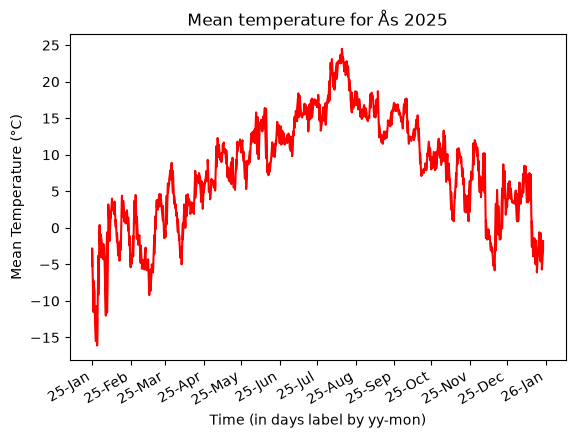

In [77]:
# Insert your own client ID here from a yaml file containing client_ID: <YOUR CLIENT ID>
with open("key.yaml", "r") as f:
    config = yaml.safe_load(f)


# making a function to request data from frost.met.no
# using code example from https://frost.met.no/python_example.html
def get_data(station_id: str, requested_data: str, referencetime: str) -> dict:
    """
    Requests a datatype for the weather ag given weather station for a given timeframe
    from https://frost.met.no/observations/v0.jsonld.

    ARGS:
        requested_data: requested_data: the data that will be requested. Full list of
        available data elements that can be requested at https://frost.met.no/elementtable.

        referencetime: the referencetime for the requested data given as dates given in the format
        2025-01-01/2025-12-31 for data from January 1st 2025 to December 31st 2025.

        station_id: the stations that the requested data should be from
    Returns:
        a requested data in the form of a dictionary
    """

    # set client ID
    client_id = config.get("client_ID")

    # data endpoint and parameters for fetch request
    endpoint = 'https://frost.met.no/observations/v0.jsonld'
    parameters = {
    'sources': station_id,
    'elements': requested_data,
    'referencetime': referencetime,
    }
    # Issue an HTTP GET request
    r = requests.get(endpoint, parameters, auth=(client_id, ''))
    # Extract JSON data
    json = r.json()

    # Verifies if data is retrived
    if r.status_code == 200:
        data = json['data']
        print('Data retrieved from frost.met.no!')
    else:
        print('Error! Returned status code %s' % r.status_code)
        print('Message: %s' % json['error']['message'])
        print('Reason: %s' % json['error']['reason'])

    return data


# Get data for mean air temperature in 2025 in Ås
data_mean = get_data('SN17850', 'mean(air_temperature P1D)', '2025-01-01/2025-12-31')

# This will return a Dataframe with all of the observations in a table format
df_mean = pd.DataFrame()
for i in range(len(data_mean)):
    row = pd.DataFrame(data_mean[i]['observations'])
    row['referenceTime'] = data_mean[i]['referenceTime']
    row['sourceId'] = data_mean[i]['sourceId']
    df_mean = pd.concat([df_mean, row], ignore_index=True)  # changed pd.append deprecated

df_mean = df_mean.reset_index()

# df_mean.head()

# Construct a plot for the data
fig, ax = plt.subplots()
plt.plot(pd.to_datetime(df_mean["referenceTime"]), df_mean["value"], color="red")

# Adding month labels to the x axis
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%y-%b"))
fig.autofmt_xdate()

# Adding title and labels and showing the plot
plt.xlabel("Time (in days label by yy-mon)")
plt.ylabel("Mean Temperature (°C)")
plt.title("Mean temperature for Ås 2025")
plt.show


In [78]:
# create a function for displaying a summary table for the data from met.no
def generate_summary_table(data: pd.DataFrame, data_name: str) -> None:
    """
    Makes a formatted summary table containing mean, median, max, min temperature
    """
    mean_temp = data["value"].mean()
    median_temp = data["value"].median()
    max_temp = data["value"].max()
    min_temp = data["value"].min()

    print(f"--- Summary for: {data_name} ---")
    print(f"{"Mean temperature":<20} {":":^1} {mean_temp:>10.2f}")
    print(f"{"Median temperature":<20} {":":^1} {median_temp:>10.2f}")
    print(f"{"Max temperature":<20} {":":^1} {max_temp:>10.2f}")
    print(f"{"Min temperature":<20} {":":^1} {min_temp:>10.2f}")


# display table for Mean air temperature in Ås 2025
generate_summary_table(df_mean, "Mean air temperature Ås 2025")

--- Summary for: Mean air temperature Ås 2025 ---
Mean temperature     :       7.90
Median temperature   :       8.35
Max temperature      :      24.50
Min temperature      :     -16.10


### Task 2

We changed the scale for percipitation from matplotlibs default scaling for the plot to use an axis from 0 to 80 mm. This reduced the amount of overlap on the two graphs on the plot without affecting any clearity.

Data retrieved from frost.met.no!


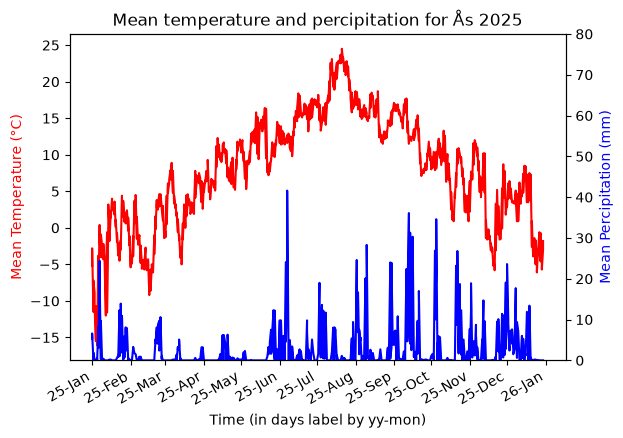

In [79]:
# Fetch percipitation data for Ås 2025
percipitation = get_data('SN17850', 'sum(precipitation_amount P1D)', '2025-01-01/2025-12-31')

df_percip = pd.DataFrame()
for i in range(len(percipitation)):
    row = pd.DataFrame(percipitation[i]['observations'])
    row['referenceTime'] = percipitation[i]['referenceTime']
    row['sourceId'] = percipitation[i]['sourceId']
    df_percip = pd.concat([df_percip, row], ignore_index=True)  # changed pd.append; deprecated

df_percip = df_percip.reset_index()

# Create a plot with two y axis
fig, ax = plt.subplots()
twin1 = ax.twinx()

# Create the mean air temperature plot
ax.plot(pd.to_datetime(df_mean["referenceTime"]), df_mean["value"], color="red")

# Create the sum percipitation plot
twin1.plot(pd.to_datetime(df_percip["referenceTime"]), df_percip["value"], color="blue",)

# Label and adjust the axis and title the plot
ax.set_ylabel("Mean Temperature (°C)", color="red")
twin1.set(ylim=[0, 80])  # set second axis scale
twin1.set_ylabel("Mean Percipitation (mm)", color="blue")
ax.set_xlabel("Time (in days label by yy-mon)")
ax.set_title("Mean temperature and percipitation for Ås 2025")

# Adjusting the x axis labeling scale to only mark the months
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%y-%b"))

# Add a slight rotation to the month labels
fig.autofmt_xdate()

# Shows the plot
plt.show()



There seemed to be a fair bit of rain during the summer in July and a number of days during the autum with percipitation over 30. 

### Task 3

Data retrieved from frost.met.no!


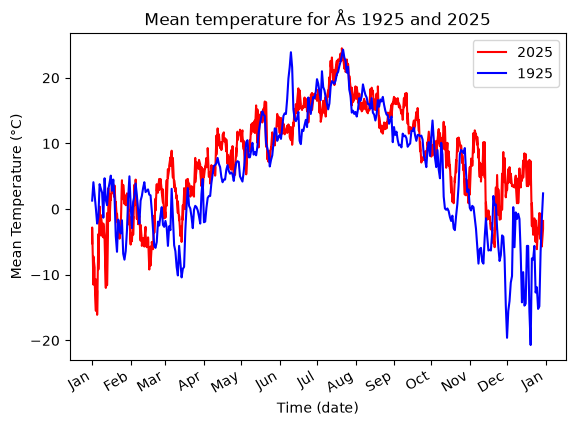

--- Summary for: Mean air temperature Ås 2025 ---
Mean temperature     :       7.90
Median temperature   :       8.35
Max temperature      :      24.50
Min temperature      :     -16.10
--- Summary for: Mean air temperature Ås 1925 ---
Mean temperature     :       5.31
Median temperature   :       5.30
Max temperature      :      24.30
Min temperature      :     -20.70


In [80]:
# code here
# Get data for mean air temperature in 1925 in Ås
data_mean_1925 = get_data('SN17850', 'mean(air_temperature P1D)', '1925-01-01/1925-12-31')

# This will return a Dataframe with all of the observations in a table format
df_mean_1925 = pd.DataFrame()
for i in range(len(data_mean_1925)):
    row = pd.DataFrame(data_mean_1925[i]['observations'])
    row['referenceTime'] = data_mean_1925[i]['referenceTime']
    row['sourceId'] = data_mean_1925[i]['sourceId']
    df_mean_1925 = pd.concat([df_mean_1925, row], ignore_index=True)  # changed pd.append deprecated

df_mean_1925 = df_mean_1925.reset_index()

# Create a plot with 2 verticle stacked subplots
fig, ax = plt.subplots()

# Create the mean air temperature plot
ax.plot(pd.to_datetime(df_mean["referenceTime"]).dt.strftime('%m%d'), df_mean["value"], color="red", label="2025")
ax.plot(pd.to_datetime(df_mean_1925["referenceTime"]).dt.strftime('%m%d'), df_mean_1925["value"], color="blue", label="1925")

ax.set_ylabel("Mean Temperature (°C)")
ax.set_xlabel("Time (date)")
ax.set_title("Mean temperature for Ås 1925 and 2025")

# Adjusting the x axis labeling scale to only mark the months
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

# Add a slight rotation to the month labels
fig.autofmt_xdate()

# Shows the plot
plt.legend()
plt.show()


generate_summary_table(df_mean, "Mean air temperature Ås 2025")
generate_summary_table(df_mean_1925, "Mean air temperature Ås 1925")

2025 was a warmer year than 1925, wither higher mean, median and higher minimum temperature. The max temperature is almost the same for both years.

### Task 4 

In [81]:
# code here
def count_heatwaves(station_id: str, station_name: str, start_and_end_date: str) -> int:
    """Collects data from frost.met.no and count the number of heatwaves in a year.
    Generates a summary yml-file.

    Args:
        station_id: ID of which wather station to collect data from.
        station_name: Name of the wather station.
        start_and_end_date: Start and end date to collect data from (YYYY-MM-DD/YYYY-MM-DD).
    Returns:
        count_heatwaves: Number of heatwaves in the given time period.
    """

    # get data for max air temperature
    data_max = get_data(station_id, 'max(air_temperature P1D)', start_and_end_date)

    # Extract dates and max temperatures from list with data
    dates = []
    max_temperatures = []

    for day in data_max:
        date = day['referenceTime']

        for observation in day['observations']:
            if observation['timeOffset'] == 'PT0H':
                max_temperature = observation['value']

                dates.append(date[:10])
                max_temperatures.append(max_temperature)

                break

    # Find all heatwaves and add the affected dates to a list
    heatwaves = []
    start_date = None
    end_date = None
    consecutive_days = 0
    count_heatwaves = 0

    for current_date, temperature in zip(dates, max_temperatures):
        if temperature >= 27:
            if consecutive_days == 0:
                start_date = current_date

            consecutive_days += 1

        else:
            if consecutive_days >= 5:
                heatwaves.append(f'{start_date} - {end_date}')
                count_heatwaves += 1

            consecutive_days = 0
            start_date = None

        end_date = current_date

    # Make a summary, formatted as the example file
    summary = {
        'dates': heatwaves,
        'station_ID': station_id,
        'station_name': station_name,
        'year': start_and_end_date.split('/')[0].split('-')[0],
    }

    # Make a yaml-file with the summary
    with open('heatwave_summary.yml', 'w') as file:
        yaml.dump(summary, file)

    return count_heatwaves


count_heatwaves('SN17850', 'ÅS', '2025-01-01/2025-12-31')

Data retrieved from frost.met.no!


1

### Task 5

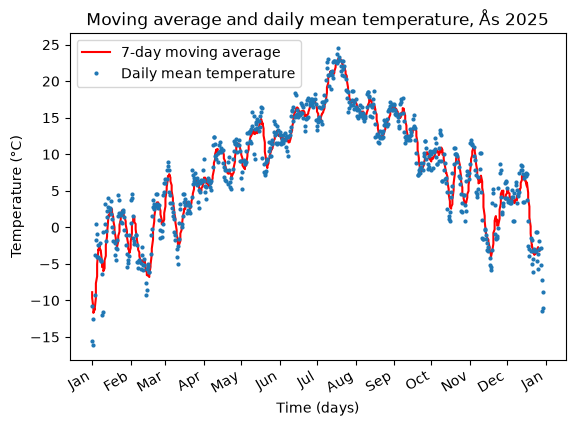

In [82]:


def moving_average_temperature(mean_temperatures: pd.Series) -> list:
    """Calculate the 7-day moving average for temperature."""
    
    average_temp = []

    for i in range(len(mean_temperatures) - 6):
        seven_day_interval = mean_temperatures[i:i + 7]
        average = sum(seven_day_interval) / 7
        average_temp.append(average)

    return average_temp


averages_2025 = moving_average_temperature(df_mean['value'])

# Finding the dates associated with the seven-day moving average
sevenday_dates = df_mean['referenceTime'].tolist()[6:]

# Finding the dates associated with the daily mean temperature
mean_dates = df_mean['referenceTime'].tolist()

# Construct a plot for the data with labeled axis
fig, ax = plt.subplots()
plt.plot(sevenday_dates, averages_2025, color='red', label='7-day moving average')
plt.plot(mean_dates, df_mean['value'], 'o', markersize=2, label='Daily mean temperature')

# Adding month labels to the x-axis
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.autofmt_xdate()

# Adding title and labels and showing the plot
plt.xlabel('Time (days)')
plt.ylabel('Temperature (°C)')
plt.title('Moving average and daily mean temperature, Ås 2025')
plt.legend()
plt.show()
